# LG HG2：原始测量与参考 SOC

这份 Notebook 直接读取你电脑已有的 LG HG2 原始数据，无需下载或解压新的数据包。

- 四种温度/工况：25°C LA92、−20°C UDDS、−10°C Mixed7、0°C Mixed7。
- LG 没有 Panasonic 的 NN 文件，因此这里明确使用 LG 的 Mixed7；两者不是同一个负载工况。
- 25°C UDDS：电压、电流、电池表面温度的全程与前 60 分钟。
- 不训练模型、不加载权重、不产生预测值，也不做滤波、平滑或重采样。

电压、电流和温度是原始实测值；SOC 按累计 Ah 计算参考值。本例选择额定容量 3.0 Ah、初始 SOC=100%，充电为正、放电为负：

SOC_reference(%) = 100 + 100 × (Ah − Ah[0]) / 3.0

没有把每条曲线强制归零。注意这是额定容量口径；如果改用某温度下实测容量，必须同步修改 Q_REF_AH 并注明依据。

LG 原始说明规定驾驶测试达到该温度 1C 实测放电容量的 95% 时结束，因此各曲线末端未必相同，更不必为零。

这份数据的 MAT 中 Wh 字段存在误标问题，本 Notebook 不使用 Wh，只使用 Time、Voltage、Current、Ah、Battery_Temp_degC。

来源：Kollmeyer 等，LG 18650HG2 Li-ion Battery Data，Version 3，2020，DOI 10.17632/cp3473x7xv.3，CC BY 4.0。
https://data.mendeley.com/datasets/cp3473x7xv/3


## 第 1 步：读取你电脑已有的 LG 数据

无需解压任何新资料包。下面已填入你之前使用的数据目录；如果移动过文件，只修改 DATA_DIR 这一行。

缺少依赖时，新建单元运行 `%pip install numpy scipy matplotlib`，然后重启内核并从头运行。


In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 110,
    "savefig.dpi": 300,
})

# 这里填你电脑里已有的 LG 数据目录。只改这一行即可。
DATA_DIR = Path(r"C:\Users\MSI-NB\研究生\Deep Lstm\battery-state-estimation\data")
if not DATA_DIR.is_dir():
    raise FileNotFoundError(f"数据目录不存在，请修改 DATA_DIR：{DATA_DIR}")
FIGURE_DIR = Path.cwd() / "figures_LGHG2"
FIGURE_DIR.mkdir(exist_ok=True)

Q_REF_AH = 3.0       # 本例使用 LG HG2 电芯的额定容量，单位 Ah。
SOC_INITIAL = 100.0  # 假定每次工况测试开始时已充满。
if Q_REF_AH <= 0:
    raise ValueError("参考容量必须大于零。")

print("数据目录：", DATA_DIR)
print("图片保存目录：", FIGURE_DIR)
print(f"参考 SOC：初始 {SOC_INITIAL:.1f}%，容量 {Q_REF_AH:.3f} Ah")


数据目录： C:\Users\MSI-NB\研究生\Deep Lstm\battery-state-estimation\data
图片保存目录： C:\Users\MSI-NB\研究生\ LGHG2_actual_curves_direct study\figures_LGHG2
参考 SOC：初始 100.0%，容量 3.000 Ah


## 第 2 步：读取完整记录并检查单位

使用 MAT 中的 `meas.Time` 作为文件内的秒数；横轴换算为分钟，不用行号冒充时间。
温度使用 `Battery_Temp_degC`（电池表面温度），不是恒温箱温度。

这里不读取包含多个工况的拼接长文件，因此不会重复计入同一段记录。


In [2]:
cases = [
    {
        "key": "25C_LA92",
        "temperature": 25,
        "cycle": "LA92",
        "suffix": "_LA92_25degC_LGHG2.mat"
    },
    {
        "key": "n20C_UDDS",
        "temperature": -20,
        "cycle": "UDDS",
        "suffix": "_UDDS_n20degC_LGHG2.mat"
    },
    {
        "key": "n10C_Mixed7",
        "temperature": -10,
        "cycle": "Mixed7",
        "suffix": "_Mixed7_n10degC_LGHG2.mat"
    },
    {
        "key": "0C_Mixed7",
        "temperature": 0,
        "cycle": "Mixed7",
        "suffix": "_Mixed7_0degC_LGHG2.mat"
    },
    {
        "key": "25C_UDDS",
        "temperature": 25,
        "cycle": "UDDS",
        "suffix": "_UDDS_25degC_LGHG2.mat"
    }
]

records = {}
fields = ["Time", "Voltage", "Current", "Ah", "Battery_Temp_degC"]
for case in cases:
    matches = sorted(p for p in DATA_DIR.rglob("*.mat")
                     if p.name.endswith(case["suffix"]))
    if len(matches) != 1:
        raise FileNotFoundError(
            f'{case["key"]} 预期匹配 1 个原始文件，实际 {len(matches)} 个。'
        )
    meas = loadmat(matches[0], squeeze_me=True,
                   struct_as_record=False)["meas"]
    d = {name: np.asarray(getattr(meas, name), dtype=float).reshape(-1)
         for name in fields}
    if len({len(v) for v in d.values()}) != 1:
        raise ValueError(f"{matches[0].name} 的字段长度不一致。")
    if any(not np.isfinite(v).all() for v in d.values()):
        raise ValueError(f"{matches[0].name} 有缺失或无穷值，请先检查。")
    if np.any(np.diff(d["Time"]) < 0):
        raise ValueError(f"{matches[0].name} 的时间存在倒退。")

    # 充电为正、放电为负；Ah 是仪器累计值，不是 SOC。
    d["SOC_reference_pct"] = (
        SOC_INITIAL + 100.0 * (d["Ah"] - d["Ah"][0]) / Q_REF_AH
    )
    d["source_file"] = matches[0].name
    records[case["key"]] = d

print(f'{"Case":<13} {"Rows":>9} {"Full time/min":>14} '
      f'{"Start SOC/%":>13} {"End SOC/%":>11} {"Pre-rest/min":>14}')
for case in cases:
    d = records[case["key"]]
    active = np.flatnonzero(d["Current"] < -0.02)
    pre_rest = ((d["Time"][active[0]] - d["Time"][0]) / 60
                if len(active) else np.nan)
    elapsed = (d["Time"][-1] - d["Time"][0]) / 60
    print(f'{case["key"]:<13} {len(d["Time"]):>9,d} {elapsed:>14.2f} '
          f'{d["SOC_reference_pct"][0]:>13.2f} '
          f'{d["SOC_reference_pct"][-1]:>11.2f} {pre_rest:>14.2f}')


Case               Rows  Full time/min   Start SOC/%   End SOC/%   Pre-rest/min
25C_LA92        100,764         168.06        100.00       13.66           0.00
n20C_UDDS        81,911         136.51        100.00       47.07           0.00
n10C_Mixed7      55,940          93.23        100.00       29.71           0.00
0C_Mixed7        61,540         102.56        100.00       22.41           0.00
25C_UDDS        159,646         266.09        100.00       13.66           0.00


## 第 3 步：四种工况的参考 SOC——完整文件

保留全部原始记录，包括末尾静置；横轴是原始 Time 换算的分钟，纵轴是 0–100 的 SOC 百分数。不同温度终止放电时的电量不同，不强制令曲线末端变成零。


已保存： 01_soc_reference_full_record.png


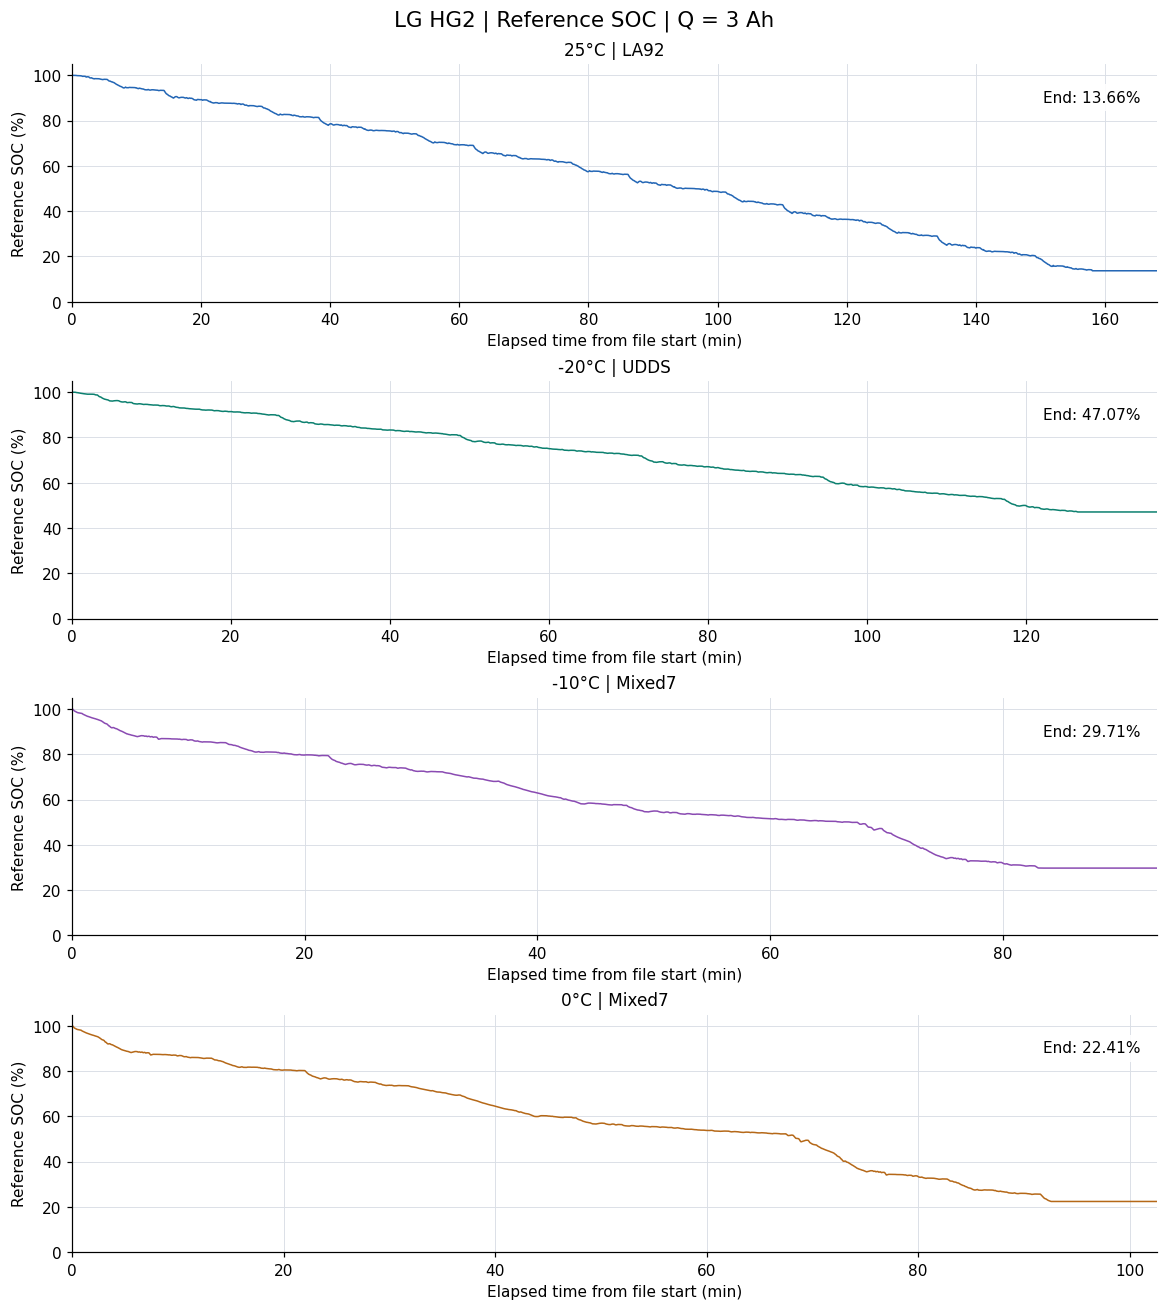

In [3]:
def plot_soc_cases(start_at_discharge=False):
    fig, axes = plt.subplots(4, 1, figsize=(10.5, 11.8),
                             constrained_layout=True)
    colors = ["#2366b5", "#0c806f", "#8a4bb2", "#b56818"]

    for ax, case, color in zip(axes, cases[:4], colors):
        d = records[case["key"]]
        start = 0
        if start_at_discharge:
            discharge = np.flatnonzero(d["Current"] < -0.02)
            # 只略去持续超过 1 分钟的工况前静置；保留放电后的静置。
            if len(discharge) and d["Time"][discharge[0]] - d["Time"][0] > 60:
                start = int(discharge[0])

        elapsed_min = (d["Time"][start:] - d["Time"][start]) / 60.0
        soc = d["SOC_reference_pct"][start:]
        ax.plot(elapsed_min, soc, color=color, linewidth=1.0,
                label="Reference SOC (Ah-based)")
        ax.set_title(f'{case["temperature"]}°C | {case["cycle"]}')
        ax.set_xlabel("Time from discharge start (min)" if start_at_discharge
                      else "Elapsed time from file start (min)")
        ax.set_ylabel("Reference SOC (%)")
        ax.set_ylim(0, 105)
        ax.set_xlim(0, elapsed_min[-1])
        ax.grid(True, color="#d9dee5", linewidth=0.6)
        ax.text(0.985, 0.89, f"End: {soc[-1]:.2f}%",
                transform=ax.transAxes, ha="right", va="top",
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.9))

    name = ("02_soc_reference_from_discharge.png" if start_at_discharge
            else "01_soc_reference_full_record.png")
    fig.suptitle("LG HG2 | Reference SOC | Q = "
                 f"{Q_REF_AH:g} Ah", fontsize=14)
    fig.savefig(FIGURE_DIR / name, dpi=300, facecolor="white")
    print("已保存：", name)
    plt.show()

plot_soc_cases(start_at_discharge=False)


## 第 4 步：25°C UDDS 的原始电压、电流、温度

按截图的顺序画六个子图：电压全程／前 60 分钟、电流全程／前 60 分钟、
电池表面温度全程／前 60 分钟。只保留原始测量曲线，不画预测线或滤波线。

此次“前 60 分钟”从这份文件起点计算。该文件没有长时间的前置静置。


已保存： 02_udds_25C_raw_voltage_current_temperature.png


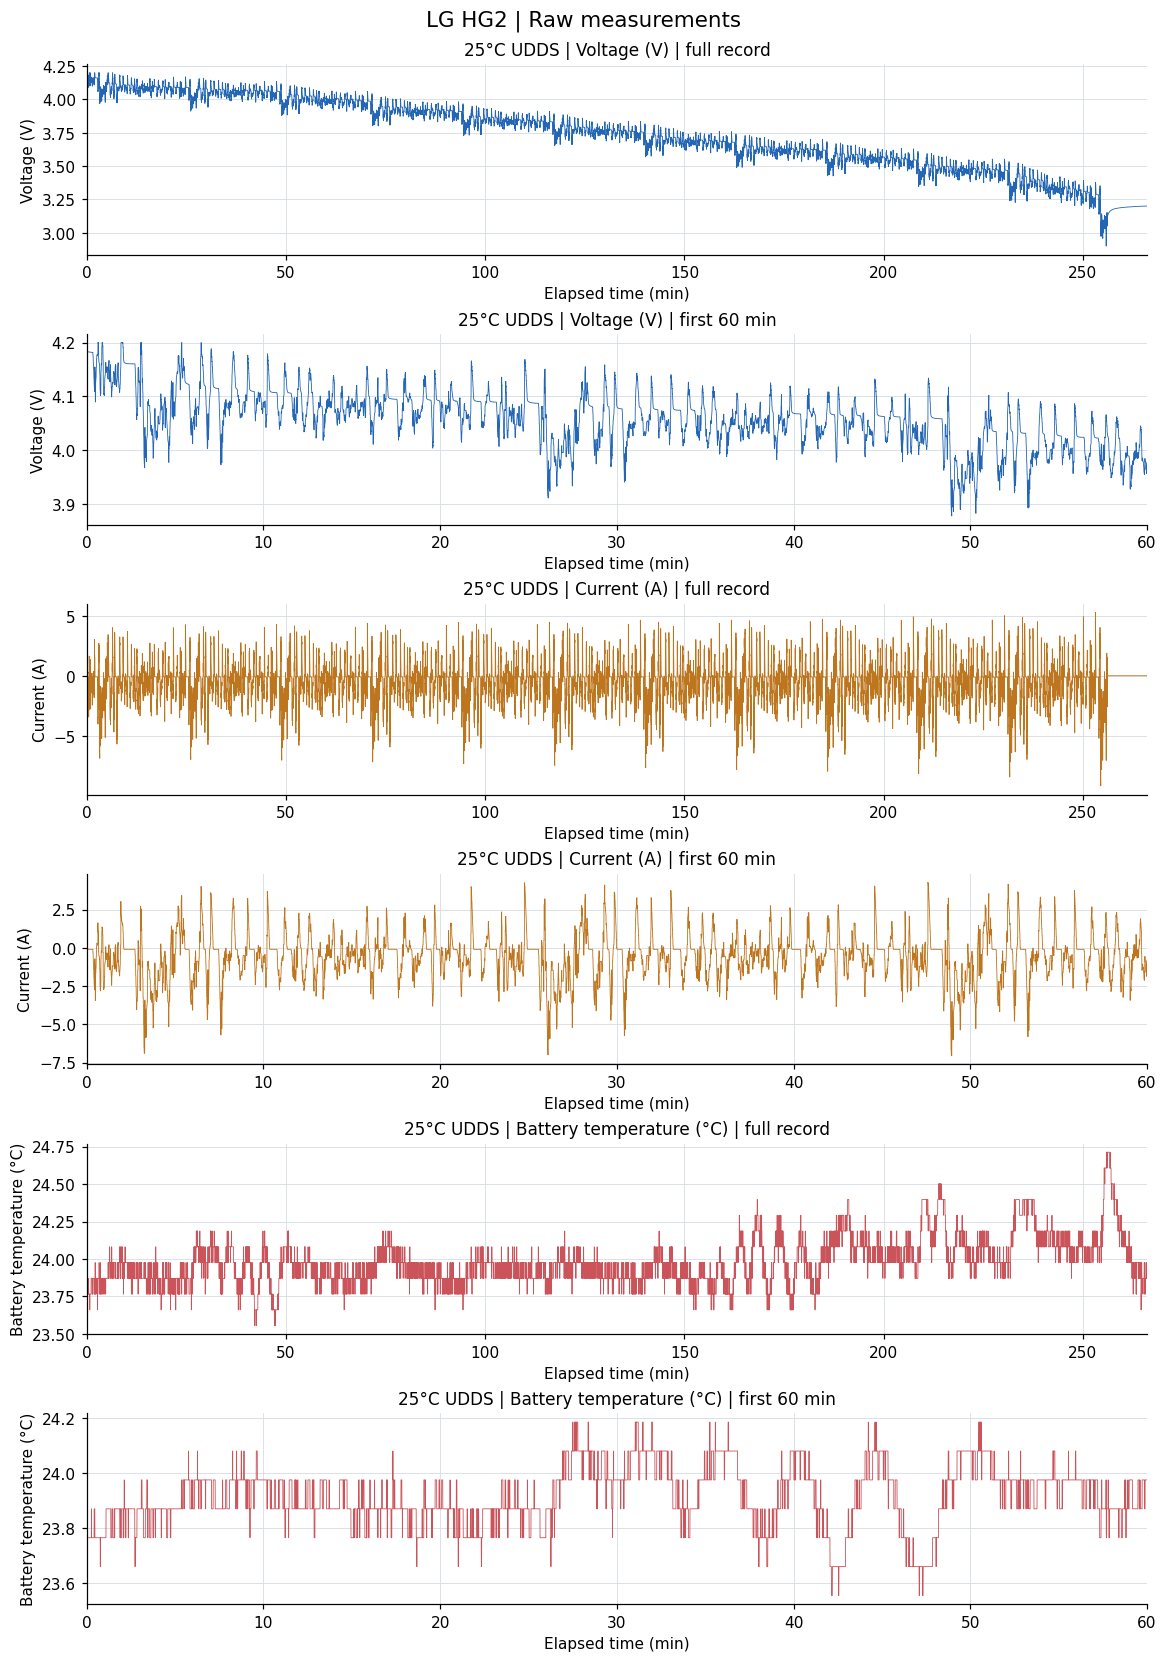

In [4]:
d = records["25C_UDDS"]
elapsed_min = (d["Time"] - d["Time"][0]) / 60.0
first_60_min = elapsed_min <= 60.0
signals = [
    ("Voltage", "Voltage (V)", "#2366b5"),
    ("Current", "Current (A)", "#bd751e"),
    ("Battery_Temp_degC", "Battery temperature (°C)", "#cb545b"),
]

fig, axes = plt.subplots(6, 1, figsize=(10.5, 15.0),
                         constrained_layout=True)
for k, (field, ylabel, color) in enumerate(signals):
    for offset, zoom in enumerate([False, True]):
        ax = axes[2 * k + offset]
        mask = first_60_min if zoom else np.ones(len(elapsed_min), dtype=bool)
        ax.plot(elapsed_min[mask], d[field][mask],
                color=color, linewidth=0.55)
        view = "first 60 min" if zoom else "full record"
        ax.set_title(f"25°C UDDS | {ylabel} | {view}")
        ax.set_xlabel("Elapsed time (min)")
        ax.set_ylabel(ylabel)
        ax.set_xlim(0, 60 if zoom else elapsed_min[-1])
        ax.grid(True, color="#d9dee5", linewidth=0.6)

fig.suptitle("LG HG2 | Raw measurements", fontsize=14)
figure_name = "02_udds_25C_raw_voltage_current_temperature.png"
fig.savefig(FIGURE_DIR / figure_name, dpi=300, facecolor="white")
print("已保存：", figure_name)
plt.show()


## 怎么解读与调整

- 曲线包含原始记录中的工况变化、短时回馈及静置；没有预测线。
- Q_REF_AH 默认 3.0 Ah，是额定容量，而不是所有温度下都能实际放出的容量。
- 不同温度下的截止电量和电压响应可以不同。Mixed7 与 Panasonic 的 NN 不是相同负载。
- 所有 PNG 保存在 figures 中，原始 MAT 不修改。
- 重开内核后按顺序运行；line width、color、figsize 可在绘图单元修改。
